### Carga de liberias para el analsis

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

## ¿El promedio dice la verdad?
Dos plantas de cacao. Requisito del cliente: Humedad maxima 2%


### Carga de la Data

In [13]:
df = pd.read_csv("../data/raw/dos_plantas.csv")
df

,planta,lote,humedad
0,A,A1,1.8
1,A,A2,1.9
2,A,A3,2.0
3,A,A4,1.9
4,A,A5,1.9
5,B,B1,1.1
6,B,B2,1.2
7,B,B3,2.9
8,B,B4,1.1
9,B,B5,1.2


### Agrupar los lotes por planta y sacar el promedio

In [14]:
df.groupby("planta")["humedad"].mean().round(2)


planta
A    1.9
B    1.5
Name: humedad, dtype: float64

### Cuenta cuántos lotes de cada planta superan el 2 % de humedad.

In [15]:
(df["humedad"] > 2).groupby(df["planta"]).sum()


planta
A    0
B    1
Name: humedad, dtype: int64

### Cada lote frente al límite de 2 %

Este gráfico muestra la humedad de los 5 lotes de cada planta, uno junto al otro:

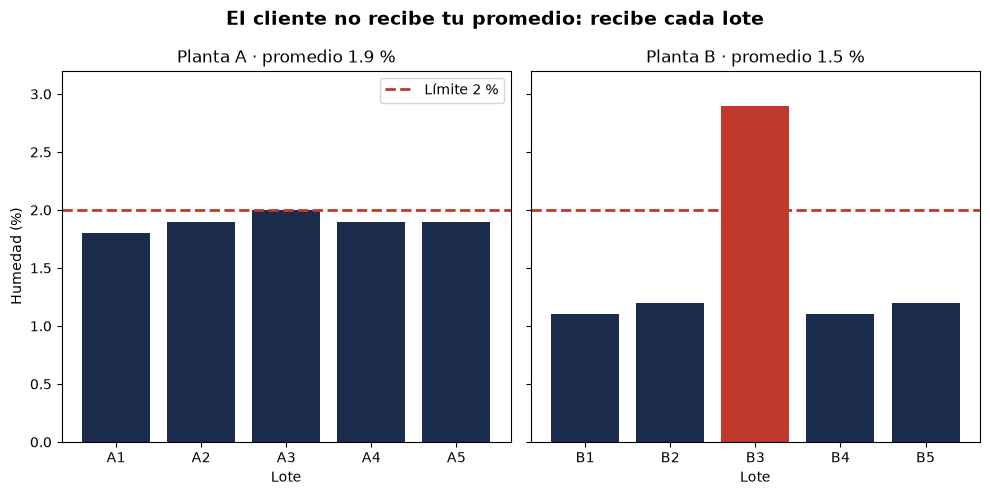

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

for ax, (planta, datos) in zip(axes, df.groupby("planta")):
    colores = ["#C0392B" if h > 2 else "#1B2B4B" for h in datos["humedad"]]
    ax.bar(datos["lote"], datos["humedad"], color=colores)
    ax.axhline(2, color="#C0392B", linestyle="--", linewidth=2, label="Límite 2 %")
    ax.set_title(f"Planta {planta} · promedio {datos['humedad'].mean():.1f} %")
    ax.set_ylim(0, 3.2)
    ax.set_xlabel("Lote")

axes[0].set_ylabel("Humedad (%)")
axes[0].legend()
fig.suptitle("El cliente no recibe tu promedio: recibe cada lote", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/dos_plantas.png", dpi=200)
plt.show()